In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as sts

dtset = pd.read_csv("Placement.csv")

dtset.isnull().sum()

sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

In [3]:
dtset['status'].value_counts()

status
Placed        148
Not Placed     67
Name: count, dtype: int64

In [4]:
dtset['salary'] = dtset['salary'].fillna(0)

In [5]:
dtset.isnull().sum()

sl_no             0
gender            0
ssc_p             0
ssc_b             0
hsc_p             0
hsc_b             0
hsc_s             0
degree_p          0
degree_t          0
workex            0
etest_p           0
specialisation    0
mba_p             0
status            0
salary            0
dtype: int64

In [6]:
#finding reason for non placement
print(dtset.groupby('status')[['ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p']].mean())

print(pd.crosstab(dtset['workex'], dtset['status']))
print(pd.crosstab(dtset['specialisation'], dtset['status']))

#conclusion
#not placed students having less mark percentage 
#57 students from 67 not placed candidates do not have work exp

                ssc_p      hsc_p   degree_p    etest_p      mba_p
status                                                           
Not Placed  57.544030  58.395522  61.134179  69.587910  61.612836
Placed      71.721486  69.926554  68.740541  73.238041  62.579392
status  Not Placed  Placed
workex                    
No              57      84
Yes             10      64
status          Not Placed  Placed
specialisation                    
Mkt&Fin                 25      95
Mkt&HR                  42      53


In [9]:
#co-relation between mba and salary
placed = dtset[dtset['status']=='Placed']

corr,pvalue = sts.pearsonr(placed['salary'],placed['mba_p'])
print ("Co-relation:", corr)
print("P value:", pvalue)


Co-relation: 0.1750129406952748
P value: 0.033376892557709474


In [10]:
#find min average salary each specialization
avg_salary = placed.groupby('specialisation')['salary'].mean()

print(avg_salary)
print("Minimum average salary specialization:", avg_salary.idxmin())

specialisation
Mkt&Fin    298852.631579
Mkt&HR     270377.358491
Name: salary, dtype: float64
Minimum average salary specialization: Mkt&HR


In [11]:
#aboce 500K salary
above_500k = placed[placed['salary'] > 500000]

print("Number of students:", len(above_500k))
print(above_500k[['salary']])

Number of students: 3
       salary
119  940000.0
150  690000.0
177  650000.0


In [12]:
#ANAVO between etest and mba
f_stat, p_value = sts.f_oneway(dtset['etest_p'], dtset['mba_p'])

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 98.64487057324706
P-value: 4.672547689133573e-21


In [13]:
#ANAVO between etest and mba - paired
f_stat, p_value = sts.ttest_rel(dtset['etest_p'], dtset['mba_p'])

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 10.840680769176654
P-value: 4.1449406968815296e-22


In [15]:
#average salary for sci tech and mkt & Hr
placed = dtset[dtset['status'] == 'Placed']

sci_tech_salary = placed.loc[placed['degree_t'] == 'Sci&Tech', 'salary']

mkt_hr_salary = placed.loc[placed['specialisation']=='Mkt&HR', 'salary']

t_stat, p_value = sts.ttest_ind( sci_tech_salary, mkt_hr_salary)

print("Sci&Tech average salary:", sci_tech_salary.mean())
print("Mkt&HR average salary:", mkt_hr_salary.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)
#pvalue less than 0.05

Sci&Tech average salary: 314609.756097561
Mkt&HR average salary: 270377.358490566
T-statistic: 2.734391160944239
P-value: 0.007496896218767113


     salary  salary_zscore
0  270000.0      -0.200292
1  200000.0      -0.951839
2  250000.0      -0.415019
4  425000.0       1.463849
7  252000.0      -0.393547


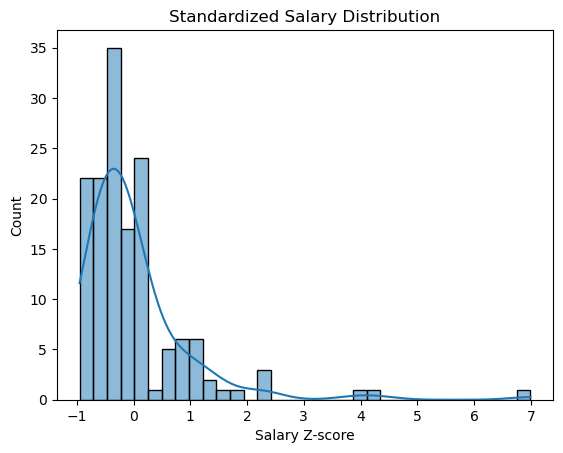

In [19]:
#normal distribution of salary
from scipy.stats import zscore

placed = dtset[dtset['status'] == 'Placed'].copy()

placed['salary_zscore'] = zscore(placed['salary'])

print(placed[['salary', 'salary_zscore']].head())

sns.histplot(placed['salary_zscore'], kde=True)
plt.title("Standardized Salary Distribution")
plt.xlabel("Salary Z-score")
plt.show()

In [20]:
#find the prabability
from scipy.stats import norm

salary = dtset.loc[dtset['status'] == 'Placed', 'salary'].dropna()

salary_mean = salary.mean()
salary_std = salary.std()

distribution = norm(salary_mean, salary_std)

probability = (distribution.cdf(900000)- distribution.cdf(700000))

print("Mean salary:", salary_mean)
print("Standard deviation:", salary_std)
print("Probability:", probability)
print("Percentage:", probability * 100)

Mean salary: 288655.4054054054
Standard deviation: 93457.45241958875
Probability: 5.377445759013888e-06
Percentage: 0.0005377445759013888


In [21]:
#compare sci tech score
sci_tech = dtset[dtset['degree_t'] == 'Sci&Tech']

t_stat, p_value = sts.ttest_rel(sci_tech['etest_p'],sci_tech['mba_p'])

print("e-test average:", sci_tech['etest_p'].mean())
print("MBA average:", sci_tech['mba_p'].mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

e-test average: 72.31050847457627
MBA average: 63.46118644067798
T-statistic: 5.0049844583693615
P-value: 5.517920600505392e-06
